<a href="https://colab.research.google.com/github/gilbert-julius-silaen/Quantum-VQE-Hydrogen/blob/main/Quantum_VQE_Hydrogen_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit qiskit-aer qiskit-nature pyscf

import qiskit
print("Laboratorium Kuantum Aktif! Versi Qiskit:", qiskit.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 64.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 64.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 24.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 48.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 68.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [qiskit-nature]
Laboratorium Kuantum Aktif! Versi Qiskit: 2.6.2


In [ ]:
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper

# 1. Mendefinisikan molekul Hidrogen (H2)
# Jarak alami antar-atom hidrogen pada kondisi stabil adalah sekitar 0.735 Angstrom
driver = PySCFDriver(
    atom="H 0 0 0; H 0 0 0.735",
    basis="sto3g",
    charge=0,
    spin=0,
    unit=DistanceUnit.ANGSTROM,
)

# Menjalankan simulasi kimia klasik untuk mengekstrak data molekul
problem = driver.run()

# 2. Menerjemahkan elektron (Fermion) menjadi bahasa bit kuantum (Qubit)
mapper = JordanWignerMapper()
hamiltonian = mapper.map(problem.hamiltonian.second_q_op())

print("✅ Molekul Hidrogen berhasil dipetakan ke matriks Kuantum!")
print(f"Jumlah Qubit yang dibutuhkan untuk simulasi ini: {hamiltonian.num_qubits}")

✅ Molekul Hidrogen berhasil dipetakan ke matriks Kuantum!
Jumlah Qubit yang dibutuhkan untuk simulasi ini: 4


In [ ]:
!pip install pylatexenc

In [ ]:
from qiskit.circuit.library import EfficientSU2

# Membangun sirkuit kuantum (Ansatz) dengan kedalaman 1 lapisan (reps=1)
ansatz = EfficientSU2(num_qubits=hamiltonian.num_qubits, reps=1, entanglement="linear")

print("Sirkuit Kuantum (Ansatz) berhasil dirakit!")

# Menggambar sirkuit menggunakan format teks ASCII standar bawaan Qiskit
display(ansatz.decompose().draw('text'))

Sirkuit Kuantum (Ansatz) berhasil dirakit!


/tmp/ipykernel_1310/1852252169.py:4: DeprecationWarning: The class ``qiskit.circuit.library.n_local.efficient_su2.EfficientSU2`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.efficient_su2 instead.
  ansatz = EfficientSU2(num_qubits=hamiltonian.num_qubits, reps=1, entanglement="linear")


┌──────────┐┌──────────┐     ┌──────────┐┌───────────┐             »
q_0: ┤ Ry(θ[0]) ├┤ Rz(θ[4]) ├──■──┤ Ry(θ[8]) ├┤ Rz(θ[12]) ├─────────────»
     ├──────────┤├──────────┤┌─┴─┐└──────────┘└┬──────────┤┌───────────┐»
q_1: ┤ Ry(θ[1]) ├┤ Rz(θ[5]) ├┤ X ├─────■───────┤ Ry(θ[9]) ├┤ Rz(θ[13]) ├»
     ├──────────┤├──────────┤└───┘   ┌─┴─┐     └──────────┘├───────────┤»
q_2: ┤ Ry(θ[2]) ├┤ Rz(θ[6]) ├────────┤ X ├──────────■──────┤ Ry(θ[10]) ├»
     ├──────────┤├──────────┤        └───┘        ┌─┴─┐    ├───────────┤»
q_3: ┤ Ry(θ[3]) ├┤ Rz(θ[7]) ├─────────────────────┤ X ├────┤ Ry(θ[11]) ├»
     └──────────┘└──────────┘                     └───┘    └───────────┘»
«                  
«q_0: ─────────────
«                  
«q_1: ─────────────
«     ┌───────────┐
«q_2: ┤ Rz(θ[14]) ├
«     ├───────────┤
«q_3: ┤ Rz(θ[15]) ├
«     └───────────┘

Memulai simulasi optimasi energi Kuantum. Harap tunggu...

✅ Simulasi Selesai!
Energi Kuantum Terendah (VQE): -1.836968 Hartree


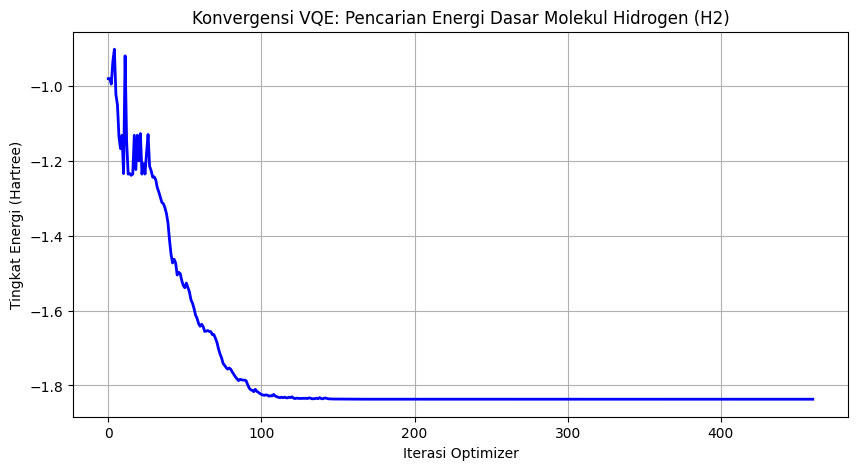

In [ ]:
from qiskit_algorithms.optimizers import COBYLA
from qiskit_algorithms import VQE
from qiskit.primitives import StatevectorEstimator
import matplotlib.pyplot as plt

# 1. Menyiapkan Estimator (Penghitung Probabilitas Kuantum Versi 2)
estimator = StatevectorEstimator()

# 2. Menyiapkan Optimizer Klasik (COBYLA) dengan maksimal 500 putaran tebakan
optimizer = COBYLA(maxiter=500)

# Variabel untuk menyimpan pergerakan energi selama proses optimasi
energy_history = []

def store_energy_history(eval_count, parameters, mean, std):
    energy_history.append(mean)

# 3. Merakit Mesin VQE Hibrida (Sirkuit Ansatz + Optimizer)
vqe = VQE(estimator, ansatz, optimizer, callback=store_energy_history)

print("Memulai simulasi optimasi energi Kuantum. Harap tunggu...")

# 4. Mengeksekusi pencarian Energi Dasar (Ground State Energy)
vqe_result = vqe.compute_minimum_eigenvalue(hamiltonian)
quantum_energy = vqe_result.eigenvalue.real

print(f"\n✅ Simulasi Selesai!")
print(f"Energi Kuantum Terendah (VQE): {quantum_energy:.6f} Hartree")

# 5. Visualisasi Hasil Konvergensi Energi
plt.figure(figsize=(10, 5))
plt.plot(energy_history, color='blue', linewidth=2)
plt.title('Konvergensi VQE: Pencarian Energi Dasar Molekul Hidrogen (H2)')
plt.xlabel('Iterasi Optimizer')
plt.ylabel('Tingkat Energi (Hartree)')
plt.grid(True)
plt.show()